**1. Conectar con Google Drive**


In [1]:
import pandas as pd, os, glob
from google.colab import drive

drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/Proyecto_Final_IA'
print(os.listdir(f'{BASE}/P1_Notas/zero_shot_v1'))

r = pd.read_csv(f'{BASE}/P1_Notas/zero_shot_v1/train_notas.csv')
print(r.shape, r.columns.tolist())

Mounted at /content/drive
['train_notas.csv']
(67, 3) ['encounter_id', 'nota_generada', 'nota_referencia']


**2. Comporvar que tenemos el fichero para generar metricas**

In [2]:
CARPETA = f'{BASE}/P2_Comparacion'
archivos = sorted(a for a in glob.glob(f'{CARPETA}/*.csv')
                  if not os.path.basename(a).startswith('metricas_'))
print([os.path.basename(a) for a in archivos])

['GEMINI36flash.csv', 'MISTRAL7b.csv', 'PHI35mini.csv', 'QWEN253b.csv', 'QWEN257b.csv']


In [3]:
!pip install -q rouge_score bert_score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


**3. Función para generar métricas**

In [4]:
from rouge_score import rouge_scorer
from bert_score import score as bert_score

def calcular_metricas(df):
    gen = df['nota_generada'].fillna('').tolist()
    ref = df['nota_referencia'].fillna('').tolist()

    # ROUGE por nota
    sc = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeLsum'], use_stemmer=True)
    filas = []
    for g, r in zip(gen, ref):
        s = sc.score(r, g)
        filas.append({
            'rouge1': s['rouge1'].fmeasure,
            'rouge2': s['rouge2'].fmeasure,
            'rougeL': s['rougeLsum'].fmeasure,
        })
    res = pd.DataFrame(filas)

    # BERTScore por nota
    _, _, F1 = bert_score(gen, ref, lang='en', batch_size=8)
    res['bertscore_f1'] = F1.numpy()

    res.insert(0, 'encounter_id', df['encounter_id'].values)
    return res

**4. Probar con el primer csv**

In [ ]:
resultados = {}
for ruta in archivos:
    modelo = os.path.basename(ruta).replace('.csv', '')
    df = pd.read_csv(ruta)
    print(f'Calculando {modelo} ({len(df)} notas)...')
    res = calcular_metricas(df)
    res.to_csv(f'{CARPETA}/metricas_{modelo}.csv', index=False)
    resultados[modelo] = res

resumen = pd.DataFrame({m: r.drop(columns='encounter_id').mean() for m, r in resultados.items()}).T
print(resumen.round(4))

Calculando QWEN257b (67 notas)...


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


          rouge1  rouge2  rougeL  bertscore_f1
QWEN257b   0.535  0.2384  0.4906        0.8732


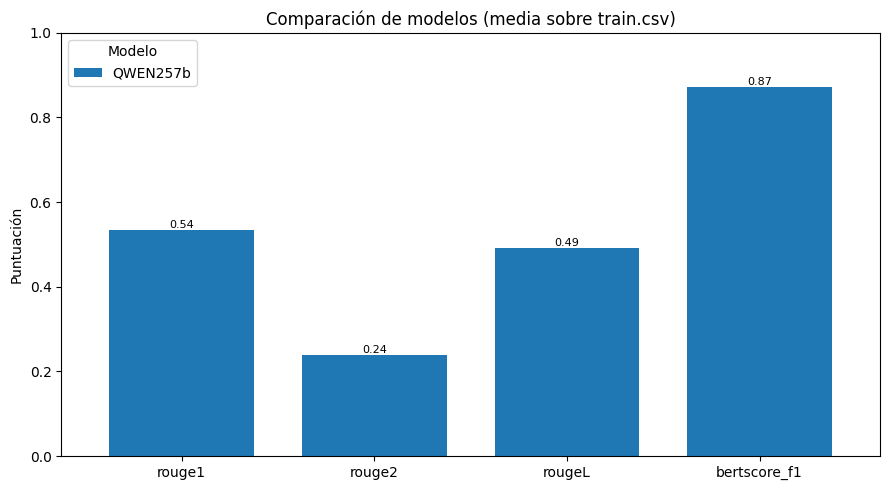

In [ ]:
import matplotlib.pyplot as plt

ax = resumen.T.plot(kind='bar', figsize=(9, 5), width=0.75)
ax.set_title('Comparación de modelos (media sobre train.csv)')
ax.set_ylabel('Puntuación')
ax.set_ylim(0, 1)
ax.legend(title='Modelo')
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8)
plt.tight_layout()
plt.savefig(f'{CARPETA}/comparacion_metricas.png', dpi=150)
plt.show()

**5. Probar otros modelos**

In [ ]:
!pip install -q -U transformers accelerate bitsandbytes

In [ ]:
import sys, gc, torch
import pandas as pd
sys.path.append(f'{BASE}/Code')
from generacion import generar_dataset

train = pd.read_csv(f'{BASE}/Dataset/challenge_data/train.csv')
print(train.shape)

(67, 4)


**5.1 Funciones para liberar Memoria**

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

def cargar_modelo(nombre):
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                             bnb_4bit_compute_dtype=torch.float16)
    tok = AutoTokenizer.from_pretrained(nombre)
    model = AutoModelForCausalLM.from_pretrained(nombre, quantization_config=bnb, device_map='auto')
    print(f'{nombre} cargado en {model.device} ({torch.cuda.memory_allocated()/1e9:.1f} GB)')
    return model, tok

def liberar(model, tok):
    del model, tok
    gc.collect()
    torch.cuda.empty_cache()

**5.2 QWEN 2.5-3B**

In [ ]:
from generacion import generar_nota

model, tok = cargar_modelo('Qwen/Qwen2.5-3B-Instruct')
print(generar_nota(model, tok, train.iloc[0]['dialogue']))

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-3B-Instruct cargado en cuda:0 (2.2 GB)
**CHIEF COMPLAINT:** Annual Exam

**HISTORY OF PRESENT ILLNESS:**  
- Age: 50 years
- Sex: Female
- Past Medical History: Congestive Heart Failure, Depression, Hypertension
- Present Symptoms: None reported
- Medication Adherence: Taking prescribed medications
- Concerns: Active lifestyle, travel, hiking

**REVIEW OF SYSTEMS:**  
- Cardiovascular: No chest pain, shortness of breath, leg swelling
- Gastrointestinal: No nausea, vomiting, abdominal pain
- Pulmonary: No cough, dyspnea
- Musculoskeletal: No joint pain
- Neurological: No suicidal thoughts, no hallucinations
- Dermatological: No rash, itching
- Genitourinary: No hematuria, dysuria

**PHYSICAL EXAM:**  
- Heart: Systolic ejection murmur grade 3/6
- Lower Extremities: One plus pitting edema
- Lungs: Clear to auscultation
- Heart: S1 and S2 heard, no additional heart murmurs

**RESULTS:**  
- Echocardiogram: Low cardiac output (45%), mitral regurgitation
- Lipid Panel: Choleste

In [ ]:
# Generar todas las notas
generar_dataset(model, tok, train, f'{CARPETA}/QWEN253b.csv')
liberar(model, tok)

5/67 (2.9 min)
10/67 (6.7 min)
15/67 (9.8 min)
20/67 (12.6 min)
25/67 (16.0 min)
30/67 (19.6 min)
35/67 (22.8 min)
40/67 (26.7 min)
45/67 (31.0 min)
50/67 (36.2 min)
55/67 (39.5 min)
60/67 (42.8 min)
65/67 (46.3 min)
Terminado: 67 notas en /content/drive/MyDrive/Proyecto_Final_IA/P2_Comparacion/QWEN253b.csv


**5.3 PHI MIni**

In [ ]:
from generacion import generar_nota

model, tok = cargar_modelo('microsoft/Phi-3.5-mini-instruct')
generar_dataset(model, tok, train, f'{CARPETA}/PHI35mini.csv')
liberar(model, tok)

config.json:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


tokenizer_config.json:   0%|          | 0.00/3.98k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

... (4 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/195 [00:00<?, ?B/s]

microsoft/Phi-3.5-mini-instruct cargado en cuda:0 (2.4 GB)
5/67 (3.7 min)
10/67 (7.3 min)
15/67 (10.3 min)
20/67 (13.2 min)
25/67 (18.8 min)
30/67 (25.6 min)
35/67 (30.0 min)
40/67 (33.6 min)
45/67 (37.1 min)
50/67 (40.7 min)
55/67 (44.0 min)
60/67 (48.3 min)
65/67 (52.4 min)
Terminado: 67 notas en /content/drive/MyDrive/Proyecto_Final_IA/P2_Comparacion/PHI35mini.csv


**5.4 Mistral**

In [ ]:
from google.colab import userdata
from huggingface_hub import login
login(userdata.get('HF_Token'))

In [ ]:
from generacion import generar_nota

model, tok = cargar_modelo('mistralai/Mistral-7B-Instruct-v0.3')
generar_dataset(model, tok, train, f'{CARPETA}/MISTRAL7b.csv')
liberar(model, tok)

config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/141k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  587kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

... (2 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

mistralai/Mistral-7B-Instruct-v0.3 cargado en cuda:0 (6.9 GB)
5/67 (4.1 min)
10/67 (8.1 min)
15/67 (11.7 min)
20/67 (14.7 min)
25/67 (22.4 min)
30/67 (28.0 min)
35/67 (31.9 min)
40/67 (36.3 min)
45/67 (40.5 min)
50/67 (45.5 min)
55/67 (49.1 min)
60/67 (53.4 min)
65/67 (57.4 min)
Terminado: 67 notas en /content/drive/MyDrive/Proyecto_Final_IA/P2_Comparacion/MISTRAL7b.csv


**6. Comparación de modelos**

In [5]:
resultados = {}
for ruta in archivos:
    modelo = os.path.basename(ruta).replace('.csv', '')
    destino = f'{CARPETA}/metricas_{modelo}.csv'
    if os.path.exists(destino):
        print(f'{modelo}: ya calculado, lo cargo')
        resultados[modelo] = pd.read_csv(destino)
    else:
        df = pd.read_csv(ruta)
        print(f'Calculando {modelo} ({len(df)} notas)...')
        resultados[modelo] = calcular_metricas(df)
        resultados[modelo].to_csv(destino, index=False)

resumen = pd.DataFrame({m: r.drop(columns='encounter_id').mean()
                        for m, r in resultados.items()}).T
print(resumen.round(4))

Calculando GEMINI36flash (67 notas)...


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


MISTRAL7b: ya calculado, lo cargo
PHI35mini: ya calculado, lo cargo
QWEN253b: ya calculado, lo cargo
QWEN257b: ya calculado, lo cargo
               rouge1  rouge2  rougeL  bertscore_f1
GEMINI36flash  0.6020  0.2955  0.5581        0.8851
MISTRAL7b      0.5350  0.2376  0.4882        0.8718
PHI35mini      0.5388  0.2221  0.5014        0.8636
QWEN253b       0.4276  0.1779  0.4024        0.8455
QWEN257b       0.5350  0.2384  0.4906        0.8732


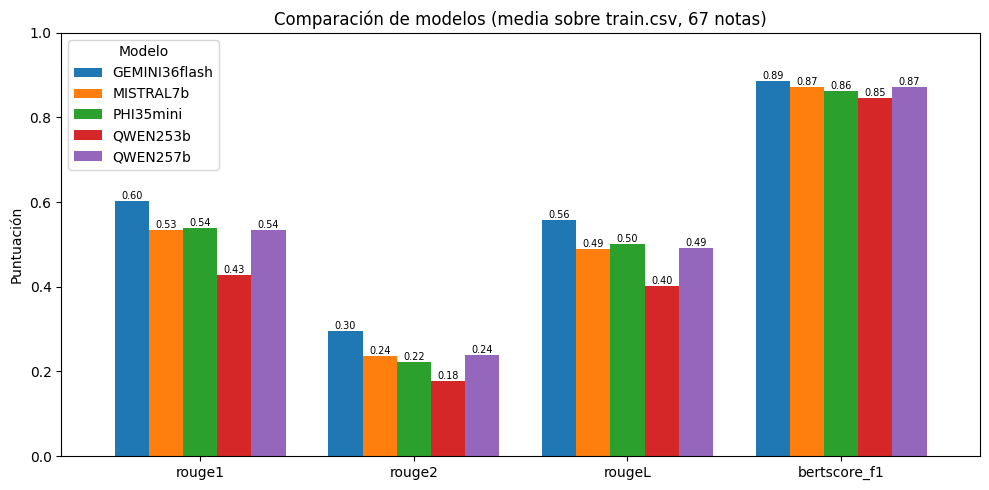

In [6]:
import matplotlib.pyplot as plt

ax = resumen.T.plot(kind='bar', figsize=(10, 5), width=0.8)
ax.set_title('Comparación de modelos (media sobre train.csv, 67 notas)')
ax.set_ylabel('Puntuación')
ax.set_ylim(0, 1)
ax.legend(title='Modelo')
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=7)
plt.tight_layout()
plt.savefig(f'{CARPETA}/comparacion_metricas.png', dpi=150)
plt.show()